# Chapter 7 — Advanced Topics and Applications

## Why this chapter matters

These methods turn social-media traces into careful, measurable evidence without treating posts as the whole population.

## Learning outcomes

- Integrate text, engagement, temporal, topic, misinformation and network features.
- Design a reproducible, ethical group project.

## Concepts in simple language

Integrated analysis can reveal temporal and topic-specific associations. Bots, language, fairness and measurement bias affect validity. Prediction estimates labels; association describes co-variation; causation needs a credible design. Responsible reports communicate uncertainty and reproducibility.

## Dataset introduction

The mini-project joins synthetic posts to user-level network metrics. All data are synthetic teaching data; they contain no real private users.

In [1]:
from pathlib import Path
import random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
current_path = Path.cwd()
if (current_path / 'data').exists(): repository_root = current_path
elif (current_path.parent / 'data').exists(): repository_root = current_path.parent
else: raise FileNotFoundError('Could not find the repository data directory.')
data_directory = repository_root / 'data'
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Data directory:', data_directory)


Python: 3.9.6 | pandas: 2.2.3
Data directory: /Users/mehrdadjalali/Documents/SRH-Courses/Modules/Social Media Analytics and Sentiment Analysis/Github/SocialMediaAnayltics/data


## Instructor-guided walkthrough

Research question: In this synthetic sample, how do sentiment, topic, engagement, misinformation labels, and network prominence vary together?

## Step-by-step Python implementation

(180, 14)


,missing
post_id,0
user_id,0
text,1
created_at,0
language,1
platform,0
likes,0
shares,0
replies,0
sentiment,0


sentiment,negative,neutral,positive
week,,,
2024-12-30,0.333333,0.333333,0.333333
2025-01-06,0.333333,0.333333,0.333333
2025-01-13,0.333333,0.333333,0.333333
2025-01-20,0.333333,0.333333,0.333333
2025-01-27,0.333333,0.333333,0.333333


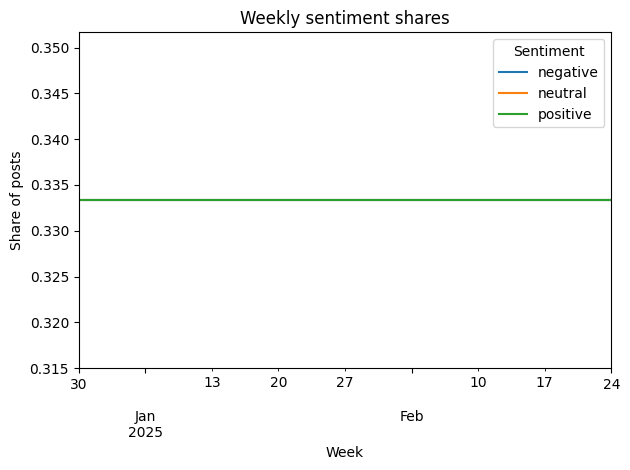

In [2]:
import networkx as nx, re
posts=pd.read_csv(data_directory/'social_media_sample.csv',parse_dates=['created_at']).drop_duplicates('post_id'); print(posts.shape); display(posts.isna().sum().to_frame('missing'))
def light_preprocess(text: object) -> str:
    """Return lowercase text with URL/mention placeholders; missing values become empty strings."""
    value='' if pd.isna(text) else str(text).lower(); value=re.sub(r'https?://\S+','URL',value); return re.sub(r'@\w+','USER',value)
posts['clean_text']=posts['text'].map(light_preprocess); posts['engagement']=posts[['likes','shares','replies']].sum(axis=1); posts['week']=posts['created_at'].dt.to_period('W').dt.start_time
trend=pd.crosstab(posts.week,posts.sentiment,normalize='index'); display(trend.head()); trend.plot(title='Weekly sentiment shares'); plt.xlabel('Week'); plt.ylabel('Share of posts'); plt.legend(title='Sentiment'); plt.tight_layout(); plt.show()

In [3]:
topic_sentiment=pd.crosstab(posts.topic,posts.sentiment,normalize='index').round(2); engagement=posts.groupby('sentiment')['engagement'].agg(['mean','median','count']).round(1); display(topic_sentiment); display(engagement)
edges=pd.read_csv(data_directory/'social_network_edges.csv'); graph=nx.from_pandas_edgelist(edges,'source','target'); degree=pd.Series(nx.degree_centrality(graph),name='degree_centrality').rename_axis('user_id').reset_index()
integrated=posts.merge(degree,on='user_id',how='left'); user_summary=integrated.groupby('user_id').agg(posts=('post_id','count'),mean_engagement=('engagement','mean'),degree_centrality=('degree_centrality','first')).sort_values('degree_centrality',ascending=False)
display(user_summary.head(10)); display(integrated.groupby('is_misinformation').agg(posts=('post_id','count'),mean_engagement=('engagement','mean'),mean_centrality=('degree_centrality','mean')).round(2))

sentiment,negative,neutral,positive
topic,,,
customer service,0.33,0.33,0.33
electric vehicles,0.33,0.33,0.33
public health,0.33,0.33,0.33
transport,0.33,0.33,0.33
university,0.33,0.33,0.33


,mean,median,count
sentiment,,,
negative,72.8,71.5,60
neutral,75.2,82.5,60
positive,76.1,79.5,60


,posts,mean_engagement,degree_centrality
user_id,,,
u31,4,65.50,0.148936
u16,4,69.50,0.148936
u01,4,65.75,0.127660
u25,4,59.50,0.127660
u10,4,71.75,0.106383
u40,4,70.00,0.106383
u30,4,69.00,0.106383
u15,4,81.25,0.106383
u45,4,74.75,0.106383


,posts,mean_engagement,mean_centrality
is_misinformation,,,
False,163,74.63,0.09
True,17,75.47,0.09


The plots and tables show sample associations. They do not show that sentiment or misinformation causes engagement, nor that central users caused diffusion. Missing users after a join, language coverage, automation, label error, and synthetic construction limit inference.

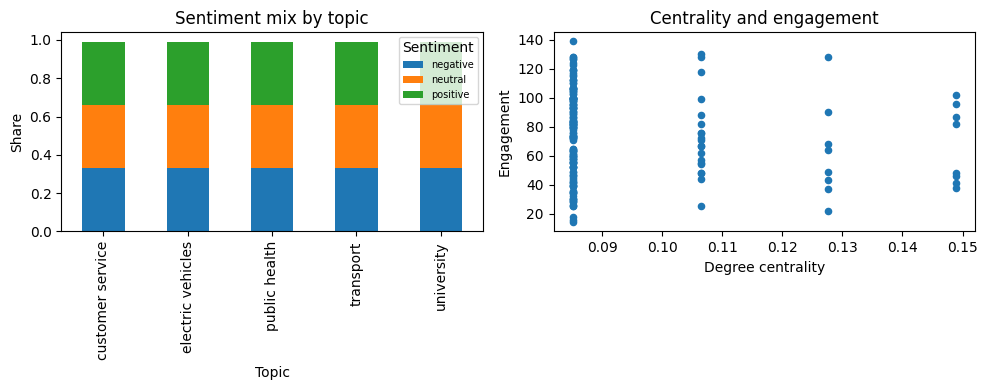

In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,4)); topic_sentiment.plot(kind='bar',stacked=True,ax=axes[0],title='Sentiment mix by topic'); axes[0].set_xlabel('Topic'); axes[0].set_ylabel('Share'); axes[0].legend(title='Sentiment',fontsize=7); integrated.plot.scatter(x='degree_centrality',y='engagement',ax=axes[1],title='Centrality and engagement'); axes[1].set_xlabel('Degree centrality'); axes[1].set_ylabel('Engagement'); plt.tight_layout(); plt.show()

## Output interpretation

Read values in context: inspect examples, sample sizes, uncertainty, and possible bias. Association is not causation.

## Common mistakes

Common errors include ignoring missing data, leakage, class imbalance, direction of edges, and treating model confidence as research certainty.

## Challenge 1: Create a topic-specific sentiment trend

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Challenge 2: Combine sentiment and network centrality

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Challenge 3: Design a mini group-project proposal

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Chapter summary

The walkthrough connected a research question to transparent data preparation, analysis, visual evidence, and cautious interpretation.

## Connection to the group project

Proposal: specify question, dataset, methods, evaluation, ethical risk, expected visualization, and limitation before analysis.